<a href="https://colab.research.google.com/github/garcialvarez/HAR/blob/main/02_preprocesado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Preprocesado de las señales inerciales

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/02_preprocesado.ipynb)

**Entrega 2 — Notebook 2 de 7.** Aquí se decide y se justifica, con datos, cada paso de preprocesado
que usan los notebooks de modelado (03–07). Responde a tres puntos de la retroalimentación de la
Entrega 1:

1. **Modalidades de información:** la serie en el *tiempo* (9 canales × 128 pasos) frente a su
   representación *tiempo-frecuencia* (espectrograma STFT). Se justifican los parámetros de la STFT.
2. **Integración numérica:** los sensores inerciales reportan *aceleración*, no velocidad ni posición.
   Se integra la aceleración, se mide la **deriva** que produce el ruido y se prueba una corrección.
3. **Validación por sujeto:** se demuestra que repartir ventanas al azar infla la accuracy, y se
   define el esquema de partición que usarán todos los modelos.

**Entradas:** ninguna (descarga el dataset). **Salidas:** figuras y tablas en este notebook.
**Orden de canales** (`INERTIAL_SIGNALS`): `body_acc` x,y,z (0–2) · `body_gyro` x,y,z (3–5) · `total_acc` x,y,z (6–8).

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

Descargando dataset (intento 1/3)...
Descargado: 61.0 MB


PosixPath('/content/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid

from data_loader import ACTIVITY_NAMES, INERTIAL_SIGNALS, load_features, load_raw_signals
from preprocessing import (CLASS_NAMES, FS, G, ChannelStandardizer, add_magnitudes, compute_stft,
                           encode_labels, integrate_velocity, subject_train_val_split)

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

X_tr, y_tr, s_tr = load_raw_signals("train")
X_te, y_te, s_te = load_raw_signals("test")
yi_tr, yi_te = encode_labels(y_tr), encode_labels(y_te)
s_tr, s_te = s_tr.values, s_te.values
print("train:", X_tr.shape, " test:", X_te.shape)


def ventana_ejemplo(act, sujeto=5):
    """Ventana central de un sujeto (la 1.ª de cada registro tiene el transitorio del filtro de gravedad)."""
    ids = np.where((y_tr.values == act) & (s_tr == sujeto))[0]
    return ids[len(ids) // 2]

train: (7352, 128, 9)  test: (2947, 128, 9)


## 1. Unidades y significado de los canales

- `total_acc`: lo que mide el acelerómetro, **incluye la gravedad**. Unidades: g.
- `body_acc`: `total_acc` menos la gravedad (estimada con un filtro pasa-bajas de 0.3 Hz). Unidades: g.
- `body_gyro`: velocidad angular. Unidades: rad/s.

Verificamos que `total_acc − body_acc` es efectivamente la gravedad: su norma debe ser ≈ 1 g.

In [5]:
stats = pd.DataFrame({"media": X_tr.mean(axis=(0, 1)), "std": X_tr.std(axis=(0, 1)),
                      "mín": X_tr.min(axis=(0, 1)), "máx": X_tr.max(axis=(0, 1))},
                     index=INERTIAL_SIGNALS).round(3)
display(stats)

gravedad = X_tr[..., 6:9] - X_tr[..., 0:3]
norma = np.linalg.norm(gravedad, axis=-1)
print(f"‖total_acc − body_acc‖: media = {norma.mean():.3f} g, desviación = {norma.std():.3f} g")

,media,std,mín,máx
body_acc_x,-0.001,0.195,-1.232,1.300
body_acc_y,-0.000,0.122,-1.345,0.976
body_acc_z,-0.000,0.107,-1.365,1.067
body_gyro_x,0.001,0.407,-4.734,4.155
body_gyro_y,-0.001,0.382,-5.974,5.746
body_gyro_z,0.000,0.256,-2.763,2.366
total_acc_x,0.805,0.414,-0.467,2.198
total_acc_y,0.029,0.391,-1.582,1.217
total_acc_z,0.086,0.358,-1.640,1.281


‖total_acc − body_acc‖: media = 1.023 g, desviación = 0.013 g


## 2. Normalización por canal

Las escalas son muy distintas (el giroscopio llega a ±6 rad/s, `body_acc` a ±1 g). Se estandariza
**por canal** (media 0, desviación 1 sobre todas las ventanas y pasos) con `ChannelStandardizer`.

Decisiones:
- **No** se normaliza cada ventana por separado: eso borraría la gravedad (la orientación del teléfono),
  que es justo lo que separa *sentado / de pie / acostado*.
- La media y la desviación se ajustan **solo con datos de entrenamiento**; con ellas se transforma
  validación y prueba. En los notebooks de modelado se ajusta con las ventanas de entrenamiento
  (sin la validación). Aquí se ajusta con todo `train` solo para ilustrar.

,media train,std train,media test,std test
body_acc_x,-0.0,1.000,-0.001,0.946
body_acc_y,-0.0,0.999,-0.001,0.985
body_acc_z,-0.0,0.999,0.002,0.894
body_gyro_x,0.0,1.000,-0.034,0.974
body_gyro_y,0.0,1.000,0.006,0.891
body_gyro_z,-0.0,1.000,0.011,0.975
total_acc_x,0.0,1.000,0.030,0.982
total_acc_y,0.0,1.000,-0.062,1.054
total_acc_z,0.0,1.000,-0.016,0.861


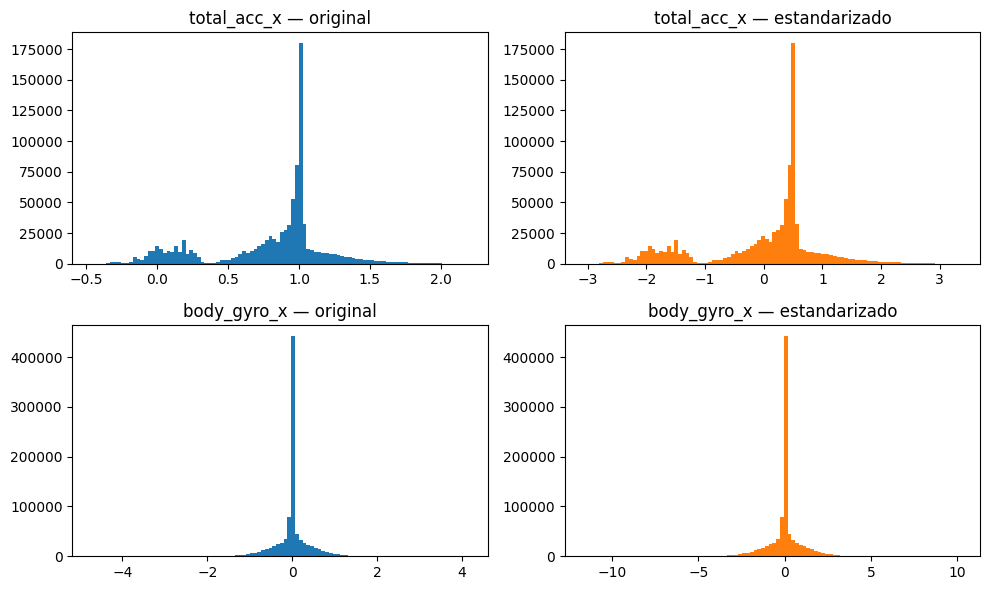

In [6]:
sc = ChannelStandardizer().fit(X_tr)
Z_tr, Z_te = sc.transform(X_tr), sc.transform(X_te)

resumen = pd.DataFrame({"media train": Z_tr.mean(axis=(0, 1)), "std train": Z_tr.std(axis=(0, 1)),
                        "media test": Z_te.mean(axis=(0, 1)), "std test": Z_te.std(axis=(0, 1))},
                       index=INERTIAL_SIGNALS).round(3)
display(resumen)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for fila, canal in enumerate(["total_acc_x", "body_gyro_x"]):
    k = INERTIAL_SIGNALS.index(canal)
    axes[fila, 0].hist(X_tr[..., k].ravel(), bins=100)
    axes[fila, 0].set_title(f"{canal} — original")
    axes[fila, 1].hist(Z_tr[..., k].ravel(), bins=100, color="C1")
    axes[fila, 1].set_title(f"{canal} — estandarizado")
fig.tight_layout()
plt.show()

## 3. Canales derivados: magnitudes

La norma de cada sensor (`|body_acc|`, `|body_gyro|`, `|total_acc|`) **no depende de la orientación**
del teléfono. Se agregan como canales 9, 10 y 11 (`add_magnitudes`: 9 → 12 canales). Abajo, la media de
`|body_acc|` por ventana separa con claridad las actividades dinámicas de las estáticas.

Forma con magnitudes: (7352, 128, 12)


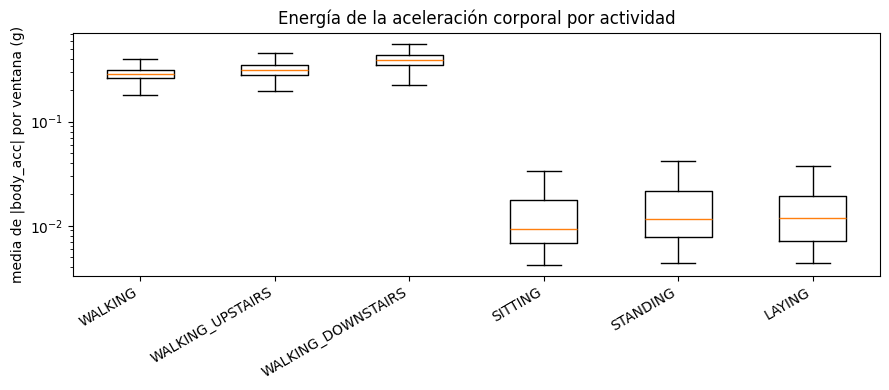

In [7]:
M_tr = add_magnitudes(X_tr)
print("Forma con magnitudes:", M_tr.shape)

media_body = M_tr[..., 9].mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([media_body[yi_tr == k] for k in range(6)], tick_labels=CLASS_NAMES, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("media de |body_acc| por ventana (g)")
ax.set_title("Energía de la aceleración corporal por actividad")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()

## 4. Integración numérica de la aceleración

**Idea.** Si integramos la aceleración una vez obtenemos velocidad; dos veces, desplazamiento. Podrían
ser variables útiles para distinguir actividades. **Problema:** la integral acumula cualquier error de la
señal. Un *offset* constante `b` en la aceleración produce una velocidad que crece como `b·t` y un
desplazamiento que crece como `b·t²/2`; el ruido de alta frecuencia se atenúa al integrar, pero el ruido
de baja frecuencia y el sesgo del sensor se amplifican. Además, la integral necesita una condición inicial
(la velocidad al comenzar la ventana), que **no conocemos**: cada ventana se integra con `v(0) = 0`, así
que la velocidad resultante es *relativa al inicio de la ventana*.

Comparamos cuatro formas de obtener la velocidad (todas con la regla del trapecio a 50 Hz):

| Método | Qué hace |
|---|---|
| A. `total_acc` sin corregir | integra la aceleración total (con gravedad) |
| B. `body_acc` sin corregir | integra la aceleración corporal tal cual |
| C. `body_acc` − media | quita el *offset* de cada ventana antes de integrar |
| D. C + pasa-altos 0.3 Hz | además filtra la velocidad (Butterworth orden 3, fase cero) para frenar la deriva |

Criterio objetivo: en las actividades **estáticas** (sentado, de pie, acostado) la velocidad real es ≈ 0,
así que cualquier velocidad que aparezca es **deriva**. En las **dinámicas** queremos conservar señal.

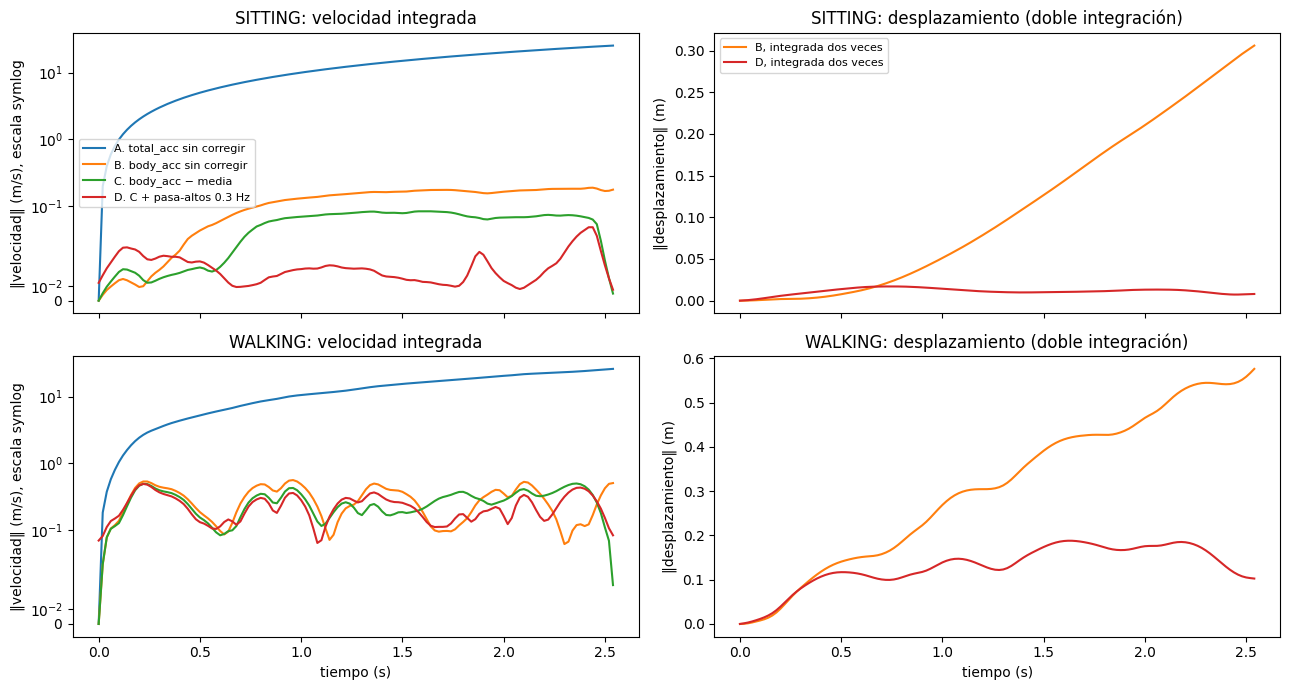

In [8]:
def vel_naive(a_g):
    """Velocidad (m/s) integrando la aceleración (g) tal cual, con v(0) = 0."""
    return cumulative_trapezoid(a_g * G, dx=1 / FS, axis=1, initial=0.0)


def desplazamiento(v):
    return cumulative_trapezoid(v, dx=1 / FS, axis=1, initial=0.0)


METODOS = {
    "A. total_acc sin corregir": lambda X: vel_naive(X[..., 6:9]),
    "B. body_acc sin corregir": lambda X: vel_naive(X[..., 0:3]),
    "C. body_acc − media": lambda X: integrate_velocity(X[..., 0:3], highpass_hz=None),
    "D. C + pasa-altos 0.3 Hz": lambda X: integrate_velocity(X[..., 0:3]),
}

t = np.arange(128) / FS
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for fila, act in enumerate(["SITTING", "WALKING"]):
    w = X_tr[[ventana_ejemplo(act)]]
    for nombre, f in METODOS.items():
        axes[fila, 0].plot(t, np.linalg.norm(f(w)[0], axis=-1), label=nombre)
    axes[fila, 0].set_yscale("symlog", linthresh=0.05)
    axes[fila, 0].set_ylabel("‖velocidad‖ (m/s), escala symlog")
    axes[fila, 0].set_title(f"{act}: velocidad integrada")
    d_naive = desplazamiento(vel_naive(w[..., 0:3]))[0]
    d_corr = desplazamiento(integrate_velocity(w[..., 0:3]))[0]
    axes[fila, 1].plot(t, np.linalg.norm(d_naive, axis=-1), label="B, integrada dos veces", color="C1")
    axes[fila, 1].plot(t, np.linalg.norm(d_corr, axis=-1), label="D, integrada dos veces", color="C3")
    axes[fila, 1].set_ylabel("‖desplazamiento‖ (m)")
    axes[fila, 1].set_title(f"{act}: desplazamiento (doble integración)")
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("tiempo (s)")
fig.tight_layout()
plt.show()

,rms estáticas (deriva) m/s,rms dinámicas m/s,cociente dinámicas/estáticas
método,,,
A. total_acc sin corregir,14.746,14.804,1.004
B. body_acc sin corregir,0.076,0.522,6.879
C. body_acc − media,0.044,0.456,10.388
D. C + pasa-altos 0.3 Hz,0.014,0.358,25.165


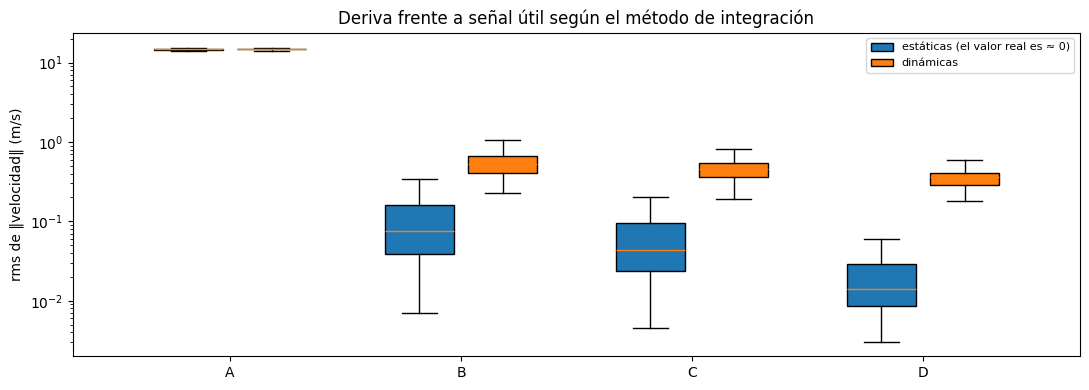

In [9]:
# Medición sobre TODAS las ventanas de entrenamiento: rms de ‖v‖ en estáticas (deriva) y dinámicas (señal)
estatica = yi_tr >= 3          # SITTING, STANDING, LAYING
filas, rms = [], {}
for nombre, f in METODOS.items():
    V = f(X_tr)
    r = np.sqrt((np.linalg.norm(V, axis=-1) ** 2).mean(axis=1))       # rms por ventana
    rms[nombre] = (r[estatica], r[~estatica])
    filas.append({"método": nombre, "rms estáticas (deriva) m/s": np.median(r[estatica]),
                  "rms dinámicas m/s": np.median(r[~estatica]),
                  "cociente dinámicas/estáticas": np.median(r[~estatica]) / np.median(r[estatica])})
tabla_int = pd.DataFrame(filas).set_index("método")
display(tabla_int.round(3))

fig, ax = plt.subplots(figsize=(11, 4))
pos = np.arange(len(METODOS))
bp1 = ax.boxplot([rms[m][0] for m in METODOS], positions=pos - 0.18, widths=0.3, patch_artist=True, showfliers=False)
bp2 = ax.boxplot([rms[m][1] for m in METODOS], positions=pos + 0.18, widths=0.3, patch_artist=True, showfliers=False)
for b in bp1["boxes"]:
    b.set_facecolor("C0")
for b in bp2["boxes"]:
    b.set_facecolor("C1")
ax.set_xticks(pos, [m.split(".")[0] for m in METODOS])
ax.set_yscale("log")
ax.set_ylabel("rms de ‖velocidad‖ (m/s)")
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["estáticas (el valor real es ≈ 0)", "dinámicas"], fontsize=8)
ax.set_title("Deriva frente a señal útil según el método de integración")
fig.tight_layout()
plt.show()

**Conclusiones sobre la integración**

- Integrar `total_acc` (método A) es inútil: la gravedad se integra como una rampa enorme.
- Aun con `body_acc`, el *offset* del sensor hace derivar la velocidad (B). Quitar la media (C) y filtrar
  con un pasa-altos (D) reduce la deriva en las actividades estáticas, que es el objetivo; la separación
  entre dinámicas y estáticas (el cociente de la tabla) mejora a medida que se corrige.
- Doble integración (desplazamiento): la deriva crece de forma cuadrática; **no se usa** como variable.
- La velocidad corregida (método D) es solo *relativa a la ventana*; no es la velocidad real del usuario.

**Decisión:** se prueba la velocidad del método D como 3 canales adicionales en el notebook 04
(experimento A3, una ablación: ¿aporta algo sobre las magnitudes?). El resultado se discute en el informe.

## 5. Representación tiempo-frecuencia (STFT)

La transformada de Fourier de tiempo corto (STFT) divide la ventana en segmentos cortos y calcula el
espectro de cada uno. Hay un **compromiso de resolución**: segmentos largos dan mejor resolución en
frecuencia pero peor en tiempo, y al revés. Se compara `nperseg = 32` (0.64 s) con `nperseg = 64`
(1.28 s), ambos con traslape 7/8. Se usa `log(1 + |STFT|)` para comprimir el rango dinámico.

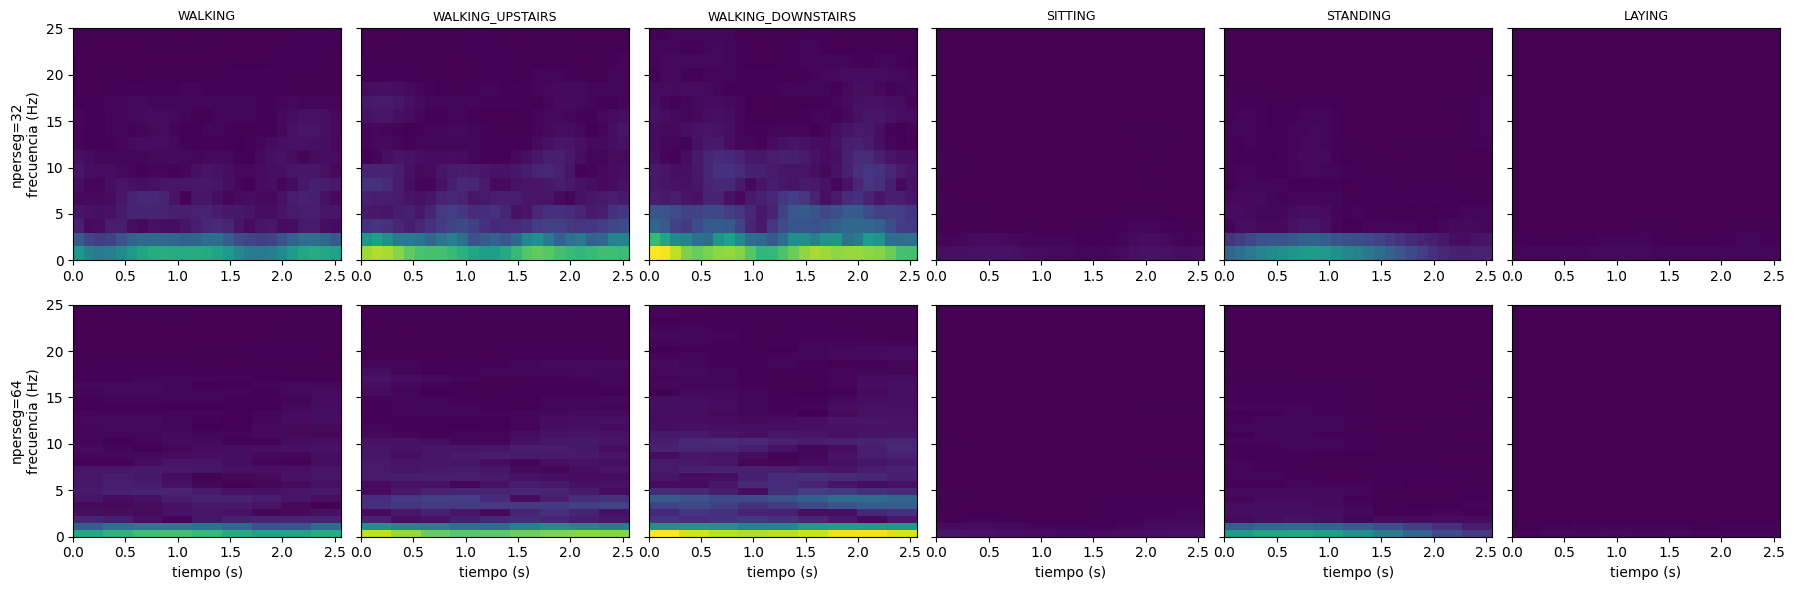

,forma (F × T'),resolución en frecuencia (Hz),duración del segmento (s),paso temporal (s)
nperseg,,,,
32,17 × 25,1.56250,0.64,0.08
64,33 × 9,0.78125,1.28,0.16


In [10]:
acts = list(ACTIVITY_NAMES.values())
W = M_tr[[ventana_ejemplo(a) for a in acts]][..., [9]]         # |body_acc| de una ventana por actividad

filas = []
fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharey="row")
for fila, nperseg in enumerate((32, 64)):
    S = compute_stft(W, nperseg=nperseg)
    noverlap = nperseg * 7 // 8
    filas.append({"nperseg": nperseg, "forma (F × T')": f"{S.shape[1]} × {S.shape[2]}",
                  "resolución en frecuencia (Hz)": FS / nperseg, "duración del segmento (s)": nperseg / FS,
                  "paso temporal (s)": (nperseg - noverlap) / FS})
    for col in range(6):
        axes[fila, col].imshow(S[col, ..., 0], origin="lower", aspect="auto", vmin=0, vmax=S.max(),
                               extent=[0, 2.56, 0, FS / 2])
        if fila == 0:
            axes[fila, col].set_title(acts[col], fontsize=9)
        if fila == 1:
            axes[fila, col].set_xlabel("tiempo (s)")
    axes[fila, 0].set_ylabel(f"nperseg={nperseg}\nfrecuencia (Hz)")
fig.tight_layout()
plt.show()
display(pd.DataFrame(filas).set_index("nperseg"))

**Lectura.** Con `nperseg = 32` la imagen es de 17 × 25 (más resolución temporal);
con `nperseg = 64` es de 33 × 9 (el doble de resolución en frecuencia, pero solo 9 pasos de tiempo).
Como la información discriminante está en bajas frecuencias (< 5 Hz), 1.56 Hz de resolución ya separa la
cadencia del paso; por eso `nperseg = 32` es la opción base y `nperseg = 64` se prueba como variante
(experimentos B1 y B2 del notebook 06). El espectrograma se calcula para los 9 canales.

## 6. Fuga de información: por qué la validación debe ser **por sujeto**

Las ventanas se traslapan 50 % y un mismo sujeto repite la misma actividad muchas veces. Si se reparten las
ventanas al azar entre entrenamiento y validación, el modelo "ve" en entrenamiento ventanas casi idénticas
a las de validación (mismo sujeto, mismo movimiento) y la accuracy se infla. Lo medimos con un Random
Forest sobre las 561 features, solo con el conjunto de entrenamiento (21 sujetos):

- **Aleatoria:** `StratifiedKFold(5, shuffle=True)` — ventanas del mismo sujeto en ambos lados.
- **Por sujeto:** `GroupKFold(5)` con `groups = sujeto` — ningún sujeto en ambos lados.

Partición aleatoria de ventanas : 0.9816 ± 0.0019
Partición por sujeto (GroupKFold): 0.9166 ± 0.0442
Inflación por fuga de información: 6.5 puntos porcentuales


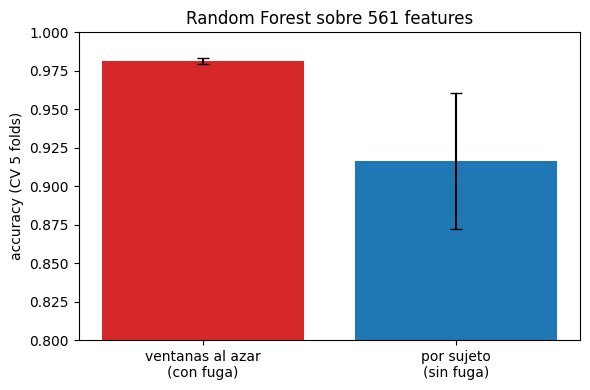

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score

X_feat, y_feat, s_feat = load_features("train")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

acc_azar = cross_val_score(rf, X_feat, y_feat, cv=StratifiedKFold(5, shuffle=True, random_state=42))
acc_sujeto = cross_val_score(rf, X_feat, y_feat, cv=GroupKFold(5), groups=s_feat)

print(f"Partición aleatoria de ventanas : {acc_azar.mean():.4f} ± {acc_azar.std():.4f}")
print(f"Partición por sujeto (GroupKFold): {acc_sujeto.mean():.4f} ± {acc_sujeto.std():.4f}")
print(f"Inflación por fuga de información: {100 * (acc_azar.mean() - acc_sujeto.mean()):.1f} puntos porcentuales")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["ventanas al azar\n(con fuga)", "por sujeto\n(sin fuga)"], [acc_azar.mean(), acc_sujeto.mean()],
       yerr=[acc_azar.std(), acc_sujeto.std()], color=["C3", "C0"], capsize=4)
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("accuracy (CV 5 folds)")
ax.set_title("Random Forest sobre 561 features")
fig.tight_layout()
plt.show()

## 7. Esquema de validación que usan todos los modelos

```
30 sujetos
 ├─ TEST oficial UCI (9 sujetos) ──────────► evaluación final, una sola vez por modelo
 └─ TRAIN oficial (21 sujetos)
     ├─ subject_train_val_split (GroupShuffleSplit 80/20 por sujeto)
     │     ├─ entrenamiento (~16 sujetos)  ─► ajusta pesos y el normalizador
     │     └─ validación    (~5 sujetos)   ─► early stopping y selección de modelo (redes)
     └─ GridSearchCV con GroupKFold(5) ───► hiperparámetros de los modelos clásicos (notebook 03)

Robustez a sujetos nuevos: GroupKFold(5) sobre los 30 sujetos (notebook 07).
```

In [12]:
tr_mask, va_mask = subject_train_val_split(s_tr, val_frac=0.2, seed=42)
sub_tr, sub_va, sub_te = set(s_tr[tr_mask]), set(s_tr[va_mask]), set(s_te)

# Ningún sujeto puede estar en dos conjuntos a la vez
assert not (sub_tr & sub_va) and not (sub_tr & sub_te) and not (sub_va & sub_te)

esquema = pd.DataFrame({
    "# sujetos": [len(sub_tr), len(sub_va), len(sub_te)],
    "# ventanas": [tr_mask.sum(), va_mask.sum(), len(s_te)],
    "sujetos": [sorted(int(s) for s in c) for c in (sub_tr, sub_va, sub_te)],
}, index=["entrenamiento", "validación", "prueba (oficial)"])
display(esquema)
print("Verificación: los tres conjuntos de sujetos son disjuntos.")

,# sujetos,# ventanas,sujetos
entrenamiento,16,5551,"[5, 6, 7, 8, 11, 14, 16, 17, 19, 21, 22, 23, 2..."
validación,5,1801,"[1, 3, 15, 25, 27]"
prueba (oficial),9,2947,"[2, 4, 9, 10, 12, 13, 18, 20, 24]"


Verificación: los tres conjuntos de sujetos son disjuntos.


## Conclusiones

In [13]:
print(f"- La gravedad (total_acc − body_acc) tiene norma {norma.mean():.2f} g: confirma el significado de los canales.")
print("- Normalización por canal, ajustada solo con entrenamiento; no por ventana (se perdería la orientación).")
print("- Magnitudes (12 canales): invariantes a la orientación del teléfono.")
print(f"- Integración: cociente señal dinámica/deriva estática = "
      f"{tabla_int.iloc[1, 2]:.1f} (B, sin corregir) → {tabla_int.iloc[3, 2]:.1f} (D, corregida). "
      "La doble integración se descarta.")
print("- STFT: nperseg=32 (17×25) como base y nperseg=64 (33×9) como variante.")
print(f"- Una partición aleatoria de ventanas da {acc_azar.mean():.3f} frente a {acc_sujeto.mean():.3f} por sujeto: "
      "la validación se hace SIEMPRE por sujeto.")

- La gravedad (total_acc − body_acc) tiene norma 1.02 g: confirma el significado de los canales.
- Normalización por canal, ajustada solo con entrenamiento; no por ventana (se perdería la orientación).
- Magnitudes (12 canales): invariantes a la orientación del teléfono.
- Integración: cociente señal dinámica/deriva estática = 6.9 (B, sin corregir) → 25.2 (D, corregida). La doble integración se descarta.
- STFT: nperseg=32 (17×25) como base y nperseg=64 (33×9) como variante.
- Una partición aleatoria de ventanas da 0.982 frente a 0.917 por sujeto: la validación se hace SIEMPRE por sujeto.


Siguiente: [`03_linea_base_features.ipynb`](03_linea_base_features.ipynb) — línea base clásica con las
561 features (Regresión Logística, Random Forest y SVM).